# Superstore Retail Sales: Exploratory Data Analysis

**Goal:** wrangle the raw file, profile missing values, and uncover the commercial patterns in customer purchase volume, monthly seasonality, category-wise revenue and discount sensitivity, ending in executive takeaways.

**Dataset:** `superstore_sales.csv` (US retail orders, Jan 2015 to Dec 2018). Keep the CSV in the same folder as this notebook.

| Section | What it covers |
|---|---|
| 1 | Load the raw file and profile missing values |
| 2 | Wrangling: split stacked sheets, parse dates, extract Year-Month, fix types, de-duplicate |
| 3 | Distributions of the numeric fields |
| 4 | Sales and profit by Category, Region, Segment and Sub-Category |
| 5 | Customer purchase volume |
| 6 | Monthly sales velocity and seasonality |
| 7 | Discount sensitivity |
| 8 | Returns cross-check |
| 9 | Executive takeaways |
| 10 | Assumptions and limitations |

In [1]:
import calendar
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 30)

def money(v):
    return f"-${abs(v):,.0f}" if v < 0 else f"${v:,.0f}"

BLUE, GREEN, RED, GREY = "#4C72B0", "#55A868", "#C44E52", "#8C8C8C"
CAT_COLORS = {"Technology": "#4C72B0", "Furniture": "#DD8452", "Office Supplies": "#55A868"}

usd = mtick.FuncFormatter(lambda x, _: f"-${abs(x):,.0f}" if x < 0 else f"${x:,.0f}")
usd_k = mtick.FuncFormatter(lambda x, _: f"-${abs(x)/1000:,.0f}K" if x < 0 else f"${x/1000:,.0f}K")

## 1. Load the raw file and profile missing values
`Row ID` is read as text on purpose. As the next cells show, this file contains non-numeric values in that column.

In [2]:
DATA_PATH = "superstore_sales.csv"

raw = pd.read_csv(DATA_PATH, dtype={"Row ID": str})
print(f"Raw shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Raw shape: 10,800 rows x 21 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [3]:
raw_nulls = raw.isna().sum().to_frame("null_count")
raw_nulls["null_%"] = raw_nulls["null_count"] / len(raw) * 100
raw_nulls[raw_nulls["null_count"] > 0]

,null_count,null_%
Order Date,806,7.462963
Ship Date,806,7.462963
Ship Mode,806,7.462963
Customer ID,806,7.462963
Customer Name,806,7.462963
Segment,806,7.462963
Country,806,7.462963
City,806,7.462963
State,806,7.462963
Postal Code,817,7.564815


**Finding:** 19 of the 21 columns show the same count of nulls (806). That is a pattern, not scattered missing data. Postal Code has 11 extra nulls on top of it. Before imputing or dropping anything, let's see *where* those rows sit.

In [4]:
null_block = raw[raw["Order Date"].isna()]
print(f"Null rows run from index {null_block.index.min():,} to {null_block.index.max():,} (one contiguous block of {len(null_block)} rows)")
print("Most common 'Row ID' values inside that block:", null_block["Row ID"].value_counts().head(3).to_dict())
print()
print("Boundary of the block (first two columns only):")
raw.iloc[9992:10002, :2]

Null rows run from index 9,994 to 10,799 (one contiguous block of 806 rows)
Most common 'Row ID' values inside that block: {'Yes': 800, 'Person': 1, 'Anna Andreadi': 1}

Boundary of the block (first two columns only):


,Row ID,Order ID
9992,9993,CA-2018-121258
9993,9994,CA-2018-119914
9994,Person,Region
9995,Anna Andreadi,West
9996,Chuck Magee,East
9997,Kelly Williams,Central
9998,Cassandra Brandow,South
9999,Returned,Order ID
10000,Yes,CA-2015-100762
10001,Yes,CA-2015-100762


**The 806 "null" rows are two other worksheets stacked underneath the orders**, which is how the Tableau Superstore workbook gets flattened into one CSV:

| Rows | Content |
|---|---|
| 0 to 9,993 | **Orders**: the actual sales line items |
| next 5 | **People**: regional managers (header row + 4 managers) |
| remaining 801 | **Returns**: header row + one `Yes` per returned order line |

Dropping or imputing these rows would be wrong: they are valid records belonging to *other tables*. The right fix is to split them apart. The Returns table is genuinely useful, and we use it in Section 8.

## 2. Data wrangling
### 2.1 Split the stacked sheets

In [5]:
is_order = raw["Order Date"].notna()
orders = raw[is_order].copy()

tail = raw[~is_order]
i_people = tail.index[tail["Row ID"] == "Person"][0]
i_returns = tail.index[tail["Row ID"] == "Returned"][0]

people = tail.loc[i_people + 1 : i_returns - 1, ["Row ID", "Order ID"]]
people.columns = ["Manager", "Region"]

returns = tail.loc[i_returns + 1 :, ["Row ID", "Order ID"]]
returns.columns = ["Returned", "Order ID"]
returns = returns.drop_duplicates("Order ID")   # the sheet repeats a returned order once per line item

print(f"orders : {len(orders):,} line items")
print(f"people : {len(people)} regional managers")
print(f"returns: {len(returns):,} distinct returned orders")
people.reset_index(drop=True)

orders : 9,994 line items
people : 4 regional managers
returns: 296 distinct returned orders


,Manager,Region
0,Anna Andreadi,West
1,Chuck Magee,East
2,Kelly Williams,Central
3,Cassandra Brandow,South


### 2.2 Fix types, parse dates, extract Year-Month

In [6]:
orders["Row ID"] = orders["Row ID"].astype(int)
orders["Quantity"] = orders["Quantity"].astype(int)

orders["Order Date"] = pd.to_datetime(orders["Order Date"], format="%m/%d/%Y")
orders["Ship Date"] = pd.to_datetime(orders["Ship Date"], format="%m/%d/%Y")

orders["Year"] = orders["Order Date"].dt.year
orders["Month"] = orders["Order Date"].dt.month
orders["Year-Month"] = orders["Order Date"].dt.to_period("M")
orders["Ship Days"] = (orders["Ship Date"] - orders["Order Date"]).dt.days

print("Order dates:", orders["Order Date"].min().date(), "to", orders["Order Date"].max().date())
orders[["Order Date", "Ship Date", "Year", "Month", "Year-Month", "Ship Days"]].head()

Order dates: 2015-01-03 to 2018-12-30


,Order Date,Ship Date,Year,Month,Year-Month,Ship Days
0,2017-11-08,2017-11-11,2017,11,2017-11,3
1,2017-11-08,2017-11-11,2017,11,2017-11,3
2,2017-06-12,2017-06-16,2017,6,2017-06,4
3,2016-10-11,2016-10-18,2016,10,2016-10,7
4,2016-10-11,2016-10-18,2016,10,2016-10,7


### 2.3 Postal Code
The only genuine missing values in the orders table are 11 Postal Codes. Postal Code was also read as a float, which drops leading zeros (New England ZIPs such as `05401` become `5401`). Both are fixed below.

In [7]:
missing_pc = orders["Postal Code"].isna()
print("Rows with missing Postal Code, by city/state:")
print(orders.loc[missing_pc, ["City", "State"]].value_counts().to_string())

# All 11 are Burlington, Vermont -> fill with its ZIP (05401). Postal Code is not used in any calculation below.
orders.loc[missing_pc & (orders["City"] == "Burlington") & (orders["State"] == "Vermont"), "Postal Code"] = 5401
orders["Postal Code"] = orders["Postal Code"].astype(int).astype(str).str.zfill(5)

print("\nRemaining nulls in the orders table:", int(orders.isna().sum().sum()))

Rows with missing Postal Code, by city/state:
City        State  
Burlington  Vermont    11

Remaining nulls in the orders table: 0


### 2.4 Duplicates and integrity checks

In [8]:
dedupe_cols = [c for c in orders.columns if c != "Row ID"]
dupes = orders[orders.duplicated(subset=dedupe_cols, keep=False)]
print(f"Exact duplicate line items (ignoring Row ID): {len(dupes) // 2 if len(dupes) else 0}")
dupes[["Row ID", "Order ID", "Customer Name", "Product Name", "Sales", "Quantity", "Discount", "Profit"]]

Exact duplicate line items (ignoring Row ID): 1


,Row ID,Order ID,Customer Name,Product Name,Sales,Quantity,Discount,Profit
3405,3406,US-2015-150119,Laurel Beltran,Global Leather Highback Executive Chair with P...,281.372,2,0.3,-12.0588
3406,3407,US-2015-150119,Laurel Beltran,Global Leather Highback Executive Chair with P...,281.372,2,0.3,-12.0588


In [9]:
checks = pd.Series({
    "Ship date earlier than order date": int((orders["Ship Date"] < orders["Order Date"]).sum()),
    "Sales <= 0": int((orders["Sales"] <= 0).sum()),
    "Quantity <= 0": int((orders["Quantity"] <= 0).sum()),
    "Discount outside 0-1": int((~orders["Discount"].between(0, 1)).sum()),
    "Order IDs linked to more than one customer": int((orders.groupby("Order ID")["Customer ID"].nunique() > 1).sum()),
    "Customer IDs with more than one name": int((orders.groupby("Customer ID")["Customer Name"].nunique() > 1).sum()),
    "Product IDs with more than one product name": int((orders.groupby("Product ID")["Product Name"].nunique() > 1).sum()),
}, name="issues found").to_frame()
checks

,issues found
Ship date earlier than order date,0
Sales <= 0,0
Quantity <= 0,0
Discount outside 0-1,0
Order IDs linked to more than one customer,0
Customer IDs with more than one name,0
Product IDs with more than one product name,32


In [10]:
df = orders.drop_duplicates(subset=dedupe_cols, keep="first").reset_index(drop=True)

print(f"Analysis table: {len(df):,} line items | {df['Order ID'].nunique():,} orders | {df['Customer ID'].nunique():,} customers")
print(f"Period: {df['Order Date'].min():%b %Y} to {df['Order Date'].max():%b %Y}")
print(f"Total sales : ${df['Sales'].sum():>12,.0f}")
print(f"Total profit: ${df['Profit'].sum():>12,.0f}  (margin {df['Profit'].sum() / df['Sales'].sum():.1%})")
print(f"Missing values remaining: {int(df.isna().sum().sum())}")

Analysis table: 9,993 line items | 5,009 orders | 793 customers
Period: Jan 2015 to Dec 2018
Total sales : $   2,296,919
Total profit: $     286,409  (margin 12.5%)
Missing values remaining: 0


### 2.5 Cleaning log

| Issue | Evidence | Action |
|---|---|---|
| People + Returns sheets stacked under the orders | 806 rows with 19 identical null counts | Split into three tables; no imputation |
| `Row ID` read as text | Contains `Person`, `Returned`, `Yes` | Cast to int on the orders table only |
| Dates stored as `M/D/YYYY` text | `object` dtype | Parsed with an explicit format; added Year, Month, Year-Month, Ship Days |
| 11 missing Postal Codes | All Burlington, VT | Filled with `05401`; ZIPs stored as zero-padded text |
| 1 exact duplicate line item | Same order, product, quantity, discount, profit | Dropped (impact on sales: about $281) |
| 32 Product IDs map to more than one name | Integrity check above | Left as is; analysis uses Category / Sub-Category, not Product ID |
| Integrity: ship-before-order, non-positive sales or quantity, discount range | All zero | None needed |

## 3. Distributions of the numeric fields

In [11]:
pd.set_option("display.float_format", "{:,.2f}".format)   # tidy number display from here on

df[["Sales", "Quantity", "Discount", "Profit"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Sales,"9,993.00",229.85,623.28,0.44,17.28,54.48,209.94,"22,638.48"
Quantity,"9,993.00",3.79,2.23,1.00,2.00,3.00,5.00,14.00
Discount,"9,993.00",0.16,0.21,0.00,0.00,0.20,0.20,0.80
Profit,"9,993.00",28.66,234.27,"-6,599.98",1.73,8.67,29.36,"8,399.98"


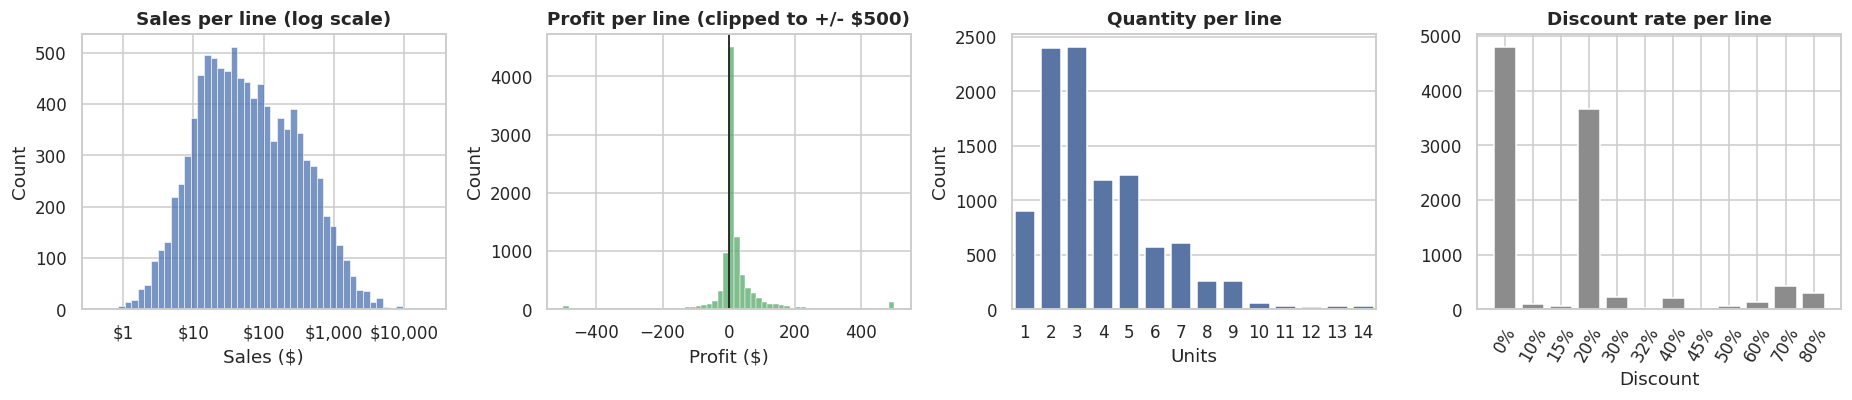

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))

sns.histplot(df["Sales"], bins=50, log_scale=True, color=BLUE, ax=axes[0])
axes[0].set_title("Sales per line (log scale)")
axes[0].set_xlabel("Sales ($)")
axes[0].xaxis.set_major_formatter(usd)

sns.histplot(df["Profit"].clip(-500, 500), bins=60, color=GREEN, ax=axes[1])
axes[1].axvline(0, color="black", lw=1)
axes[1].set_title("Profit per line (clipped to +/- $500)")
axes[1].set_xlabel("Profit ($)")

sns.countplot(x=df["Quantity"], color=BLUE, ax=axes[2])
axes[2].set_title("Quantity per line")
axes[2].set_xlabel("Units")
axes[2].set_ylabel("Count")

disc_counts = df["Discount"].value_counts().sort_index()
axes[3].bar([f"{d:.0%}" for d in disc_counts.index], disc_counts.values, color=GREY)
axes[3].set_title("Discount rate per line")
axes[3].set_xlabel("Discount")
axes[3].tick_params(axis="x", rotation=60)

fig.tight_layout()
plt.show()

**Observations**
- Sales per line is heavily right-skewed: the median line is about $54, the mean about $230, and the largest is $22.6K. Averages alone would mislead, so medians are quoted where it matters.
- Profit per line is centred just above zero with long tails in both directions (worst line: -$6.6K, best: +$8.4K).
- Quantity is small (mostly 2 to 5 units). Discounting is concentrated at two points: 48% of lines carry no discount and 37% carry exactly 20%. Everything from 30% to 80% is a small tail, and, as Section 7 shows, a costly one.

## 4. Sales and profit by Category, Region and Segment

In [13]:
def summarize(frame, by):
    return (frame.groupby(by, observed=True)
                 .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                      Orders=("Order ID", "nunique"), Lines=("Row ID", "count"),
                      Avg_Discount_pct=("Discount", lambda s: s.mean() * 100))
                 .assign(Margin_pct=lambda t: t["Profit"] / t["Sales"] * 100,
                         Sales_share_pct=lambda t: t["Sales"] / t["Sales"].sum() * 100,
                         Profit_share_pct=lambda t: t["Profit"] / t["Profit"].sum() * 100)
                 .sort_values("Sales", ascending=False))

by_cat = summarize(df, "Category")
by_region = summarize(df, "Region")
by_segment = summarize(df, "Segment")
by_cat

,Sales,Profit,Orders,Lines,Avg_Discount_pct,Margin_pct,Sales_share_pct,Profit_share_pct
Category,,,,,,,,
Technology,"836,154.03","145,454.95",1544,1847,13.23,17.40,36.40,50.79
Furniture,"741,718.42","18,463.33",1764,2120,17.39,2.49,32.29,6.45
Office Supplies,"719,047.03","122,490.80",3742,6026,15.73,17.04,31.30,42.77


In [14]:
by_region

,Sales,Profit,Orders,Lines,Avg_Discount_pct,Margin_pct,Sales_share_pct,Profit_share_pct
Region,,,,,,,,
West,"725,457.82","108,418.45",1611,3203,10.93,14.94,31.58,37.85
East,"678,499.87","91,534.84",1401,2847,14.53,13.49,29.54,31.96
Central,"501,239.89","39,706.36",1175,2323,24.04,7.92,21.82,13.86
South,"391,721.91","46,749.43",822,1620,14.73,11.93,17.05,16.32


In [15]:
by_segment

,Sales,Profit,Orders,Lines,Avg_Discount_pct,Margin_pct,Sales_share_pct,Profit_share_pct
Segment,,,,,,,,
Consumer,"1,161,401.34","134,119.21",2586,5191,15.81,11.55,50.56,46.83
Corporate,"706,146.37","91,979.13",1514,3020,15.82,13.03,30.74,32.11
Home Office,"429,371.78","60,310.74",909,1782,14.70,14.05,18.69,21.06


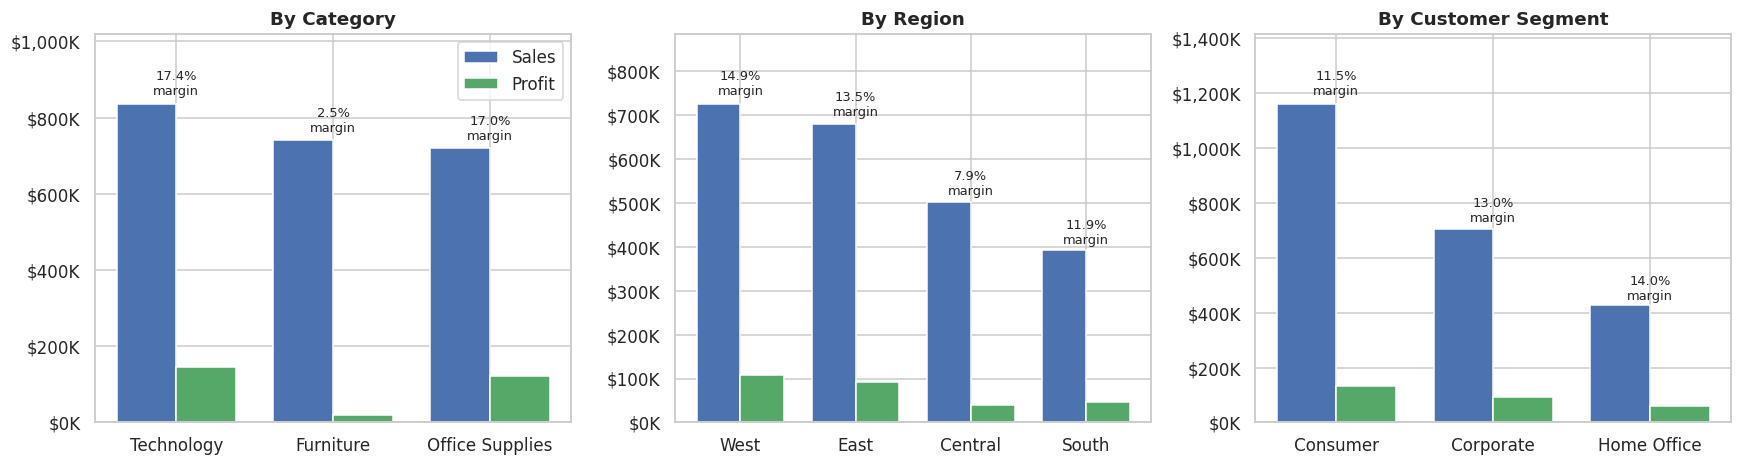

In [16]:
def sales_profit_panel(ax, tbl, title):
    x = np.arange(len(tbl))
    w = 0.38
    ax.bar(x - w / 2, tbl["Sales"], w, label="Sales", color=BLUE)
    ax.bar(x + w / 2, tbl["Profit"], w, label="Profit", color=GREEN)
    for i, (s, m) in enumerate(zip(tbl["Sales"], tbl["Margin_pct"])):
        ax.text(i, s * 1.02, f"{m:.1f}%\nmargin", ha="center", va="bottom", fontsize=8.5)
    ax.set_xticks(x)
    ax.set_xticklabels(tbl.index)
    ax.yaxis.set_major_formatter(usd_k)
    ax.set_ylim(0, tbl["Sales"].max() * 1.22)
    ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
sales_profit_panel(axes[0], by_cat, "By Category")
sales_profit_panel(axes[1], by_region, "By Region")
sales_profit_panel(axes[2], by_segment, "By Customer Segment")
axes[0].legend(loc="upper right")
fig.tight_layout()
plt.show()

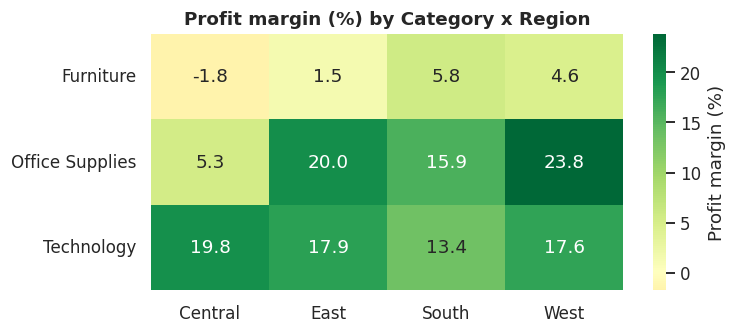

In [17]:
cat_region = df.pivot_table(index="Category", columns="Region", values=["Sales", "Profit"], aggfunc="sum")
margin_matrix = cat_region["Profit"] / cat_region["Sales"] * 100

fig, ax = plt.subplots(figsize=(7, 3.2))
sns.heatmap(margin_matrix, annot=True, fmt=".1f", cmap="RdYlGn", center=0,
            cbar_kws={"label": "Profit margin (%)"}, ax=ax)
ax.set_title("Profit margin (%) by Category x Region")
ax.set_xlabel("")
ax.set_ylabel("")
fig.tight_layout()
plt.show()

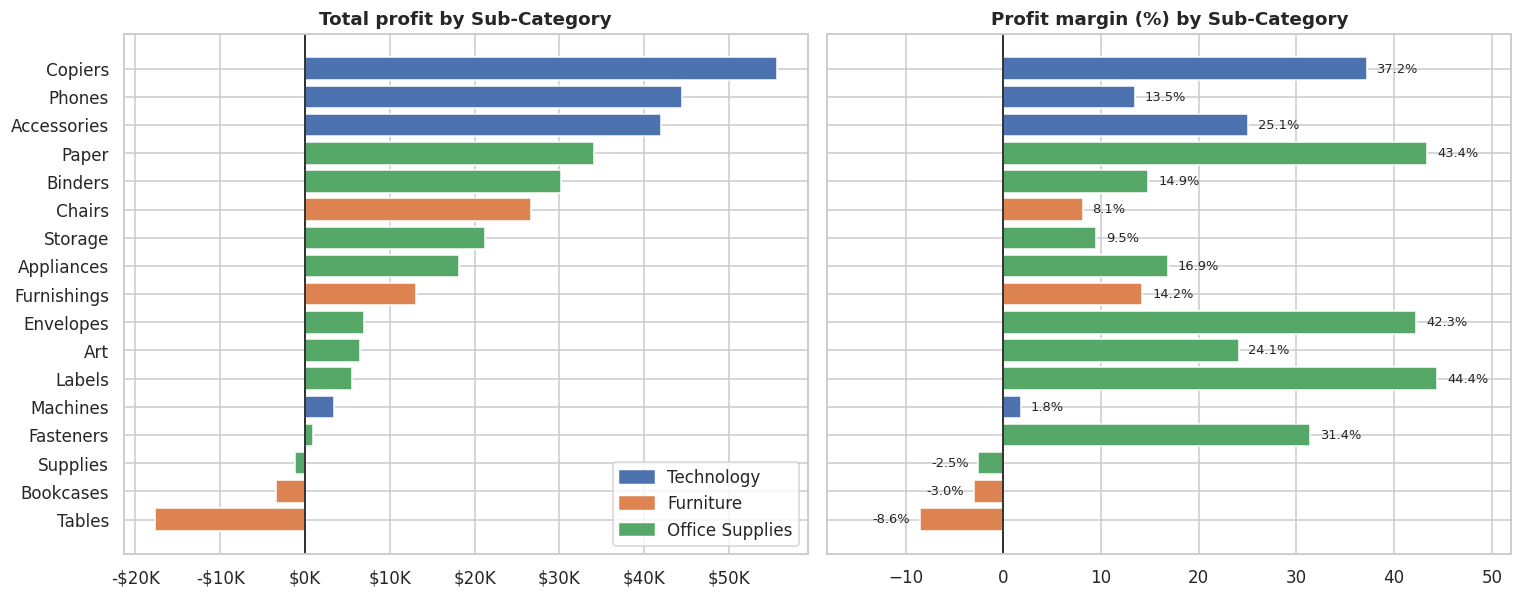

In [18]:
sub = summarize(df, ["Category", "Sub-Category"]).reset_index().sort_values("Profit")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), sharey=True)
colors = sub["Category"].map(CAT_COLORS)

axes[0].barh(sub["Sub-Category"], sub["Profit"], color=colors)
axes[0].axvline(0, color="black", lw=1)
axes[0].xaxis.set_major_formatter(usd_k)
axes[0].set_title("Total profit by Sub-Category")

axes[1].barh(sub["Sub-Category"], sub["Margin_pct"], color=colors)
axes[1].axvline(0, color="black", lw=1)
axes[1].set_title("Profit margin (%) by Sub-Category")
for y, m in enumerate(sub["Margin_pct"]):
    axes[1].text(m + (1 if m >= 0 else -1), y, f"{m:.1f}%", va="center", ha="left" if m >= 0 else "right", fontsize=8.5)
axes[1].set_xlim(-18, 52)

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CAT_COLORS.values()]
axes[0].legend(handles, CAT_COLORS.keys(), loc="lower right")
fig.tight_layout()
plt.show()

**Observations**
- **Revenue is evenly split across the three categories** (Technology 36%, Furniture 32%, Office Supplies 31%), but **profit is not**: Technology and Office Supplies earn 17.4% and 17.0% margins, while Furniture earns just 2.5%. Furniture is 32% of sales and only 6% of profit.
- Inside Furniture, **Tables (-8.6%) and Bookcases (-3.0%) lose money**; Supplies (Office Supplies) is the third loss-maker at -2.5%. Copiers (37%), Paper (43%), Labels (44%) and Envelopes (42%) are the margin stars, although Labels and Envelopes are tiny in revenue terms.
- **Region:** West leads on both sales ($725K) and margin (14.9%). **Central is the weak spot at 7.9%**, and it is Furniture there that turns negative (-1.8%) while Office Supplies earns only 5.3%.
- **Segment:** Consumer is half of sales (51%) but has the lowest margin (11.5%); Home Office is the smallest segment (19%) with the highest margin (14.0%).

## 5. Customer purchase volume

In [19]:
cust = (df.groupby(["Customer ID", "Customer Name"])
          .agg(Orders=("Order ID", "nunique"), Units=("Quantity", "sum"),
               Sales=("Sales", "sum"), Profit=("Profit", "sum"))
          .reset_index()
          .sort_values("Sales", ascending=False)
          .reset_index(drop=True))
cust["Margin_pct"] = cust["Profit"] / cust["Sales"] * 100
cust["Cum_Sales_Share"] = cust["Sales"].cumsum() / cust["Sales"].sum()

n = len(cust)
top10 = cust["Sales"].head(round(0.10 * n)).sum() / cust["Sales"].sum()
top20 = cust["Sales"].head(round(0.20 * n)).sum() / cust["Sales"].sum()
loss_customers = cust[cust["Profit"] < 0]

print(f"Customers: {n}")
print(f"Orders per customer: mean {cust['Orders'].mean():.1f}, median {cust['Orders'].median():.0f}; customers with a single order: {(cust['Orders'] == 1).sum()}")
print(f"Sales per customer: mean ${cust['Sales'].mean():,.0f}, median ${cust['Sales'].median():,.0f}")
print(f"Top 10% of customers -> {top10:.1%} of sales | top 20% -> {top20:.1%}")
print(f"Net loss-making customers: {len(loss_customers)} ({len(loss_customers) / n:.1%}); "
      f"they bring {loss_customers['Sales'].sum() / cust['Sales'].sum():.1%} of sales and {money(loss_customers['Profit'].sum())} of profit")
cust.head(10)[["Customer Name", "Orders", "Units", "Sales", "Profit", "Margin_pct"]]

Customers: 793
Orders per customer: mean 6.3, median 6; customers with a single order: 12
Sales per customer: mean $2,896, median $2,256
Top 10% of customers -> 30.6% of sales | top 20% -> 48.1%
Net loss-making customers: 155 (19.5%); they bring 17.1% of sales and -$71,212 of profit


,Customer Name,Orders,Units,Sales,Profit,Margin_pct
0,Sean Miller,5,50,"25,043.05","-1,980.74",-7.91
1,Tamara Chand,5,42,"19,052.22","8,981.32",47.14
2,Raymond Buch,6,71,"15,117.34","6,976.10",46.15
3,Tom Ashbrook,4,36,"14,595.62","4,703.79",32.23
4,Adrian Barton,10,73,"14,473.57","5,444.81",37.62
5,Ken Lonsdale,12,113,"14,175.23",806.86,5.69
6,Sanjit Chand,9,87,"14,142.33","5,757.41",40.71
7,Hunter Lopez,6,50,"12,873.30","5,622.43",43.68
8,Sanjit Engle,11,78,"12,209.44","2,650.68",21.71
9,Christopher Conant,5,34,"12,129.07","2,177.05",17.95


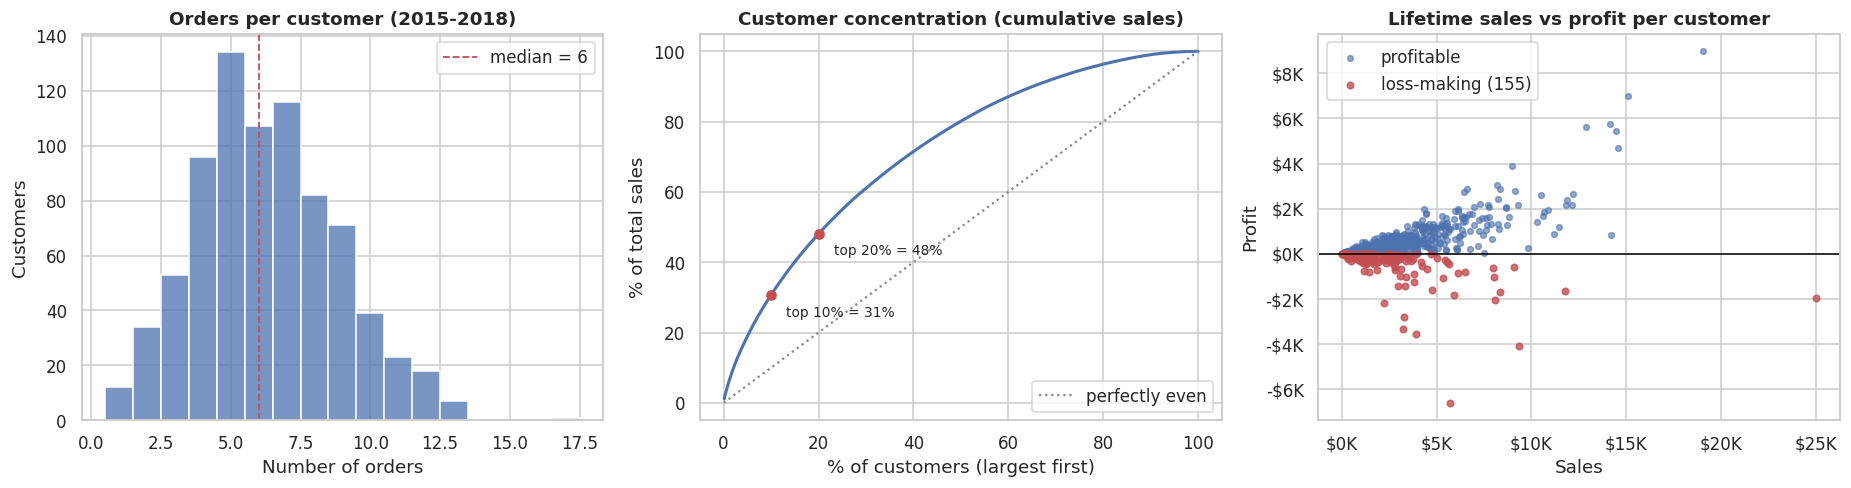

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

# (a) orders per customer
sns.histplot(cust["Orders"], discrete=True, color=BLUE, ax=axes[0])
axes[0].axvline(cust["Orders"].median(), color=RED, ls="--", lw=1.2, label=f"median = {cust['Orders'].median():.0f}")
axes[0].set_title("Orders per customer (2015-2018)")
axes[0].set_xlabel("Number of orders")
axes[0].set_ylabel("Customers")
axes[0].legend()

# (b) cumulative sales share
x = np.arange(1, n + 1) / n * 100
axes[1].plot(x, cust["Cum_Sales_Share"] * 100, color=BLUE, lw=2)
axes[1].plot([0, 100], [0, 100], color=GREY, ls=":", label="perfectly even")
for p, v in [(10, top10), (20, top20)]:
    axes[1].scatter([p], [v * 100], color=RED, zorder=5)
    axes[1].annotate(f"top {p}% = {v:.0%}", (p, v * 100), textcoords="offset points", xytext=(10, -14), fontsize=9)
axes[1].set_title("Customer concentration (cumulative sales)")
axes[1].set_xlabel("% of customers (largest first)")
axes[1].set_ylabel("% of total sales")
axes[1].legend(loc="lower right")

# (c) sales vs profit per customer
is_loss = cust["Profit"] < 0
axes[2].scatter(cust.loc[~is_loss, "Sales"], cust.loc[~is_loss, "Profit"], s=14, alpha=0.6, color=BLUE, label="profitable")
axes[2].scatter(cust.loc[is_loss, "Sales"], cust.loc[is_loss, "Profit"], s=18, alpha=0.8, color=RED, label=f"loss-making ({is_loss.sum()})")
axes[2].axhline(0, color="black", lw=1)
axes[2].xaxis.set_major_formatter(usd_k)
axes[2].yaxis.set_major_formatter(usd_k)
axes[2].set_title("Lifetime sales vs profit per customer")
axes[2].set_xlabel("Sales")
axes[2].set_ylabel("Profit")
axes[2].legend()

fig.tight_layout()
plt.show()

In [21]:
# Why is the largest customer by revenue loss-making?
top_name = cust.loc[0, "Customer Name"]
(df[df["Customer Name"] == top_name]
   .groupby("Sub-Category")
   .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Avg_Discount_pct=("Discount", lambda s: s.mean() * 100))
   .sort_values("Profit")
   .head(4))

,Sales,Profit,Avg_Discount_pct
Sub-Category,,,
Machines,"23,459.78","-1,827.50",50.00
Storage,663.07,-165.77,20.00
Binders,99.59,-82.99,70.00
Supplies,3.49,-0.70,20.00


**Observations**
- The base is **loyal and broad**: 793 customers, only 12 bought once, and the typical customer placed about 6 orders over four years (median 6, mean 6.3).
- Revenue is **moderately concentrated, not a classic 80/20**: the top 10% of customers deliver 31% of sales and the top 20% deliver 48%. Losing a handful of accounts would not hurt much; the revenue is spread out.
- **Volume is not the same as value:** 155 customers (20%) are net loss-making. They account for 17% of sales and destroy about $71K of profit. The biggest customer by revenue (Sean Miller, $25K) is one of them, driven by Machines purchases made at an average 50% discount.

## 6. Monthly sales velocity and seasonality
### 6.1 Annual trend

In [22]:
annual = (df.groupby("Year")
            .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"))
            .assign(Margin_pct=lambda t: t["Profit"] / t["Sales"] * 100,
                    Sales_YoY_pct=lambda t: t["Sales"].pct_change() * 100))
annual

,Sales,Profit,Orders,Margin_pct,Sales_YoY_pct
Year,,,,,
2015,"483,966.13","49,556.03",969,10.24,NaN
2016,"470,532.51","61,618.60",1038,13.10,-2.78
2017,"609,205.60","81,795.17",1315,13.43,29.47
2018,"733,215.26","93,439.27",1687,12.74,20.36


### 6.2 Monthly sales velocity

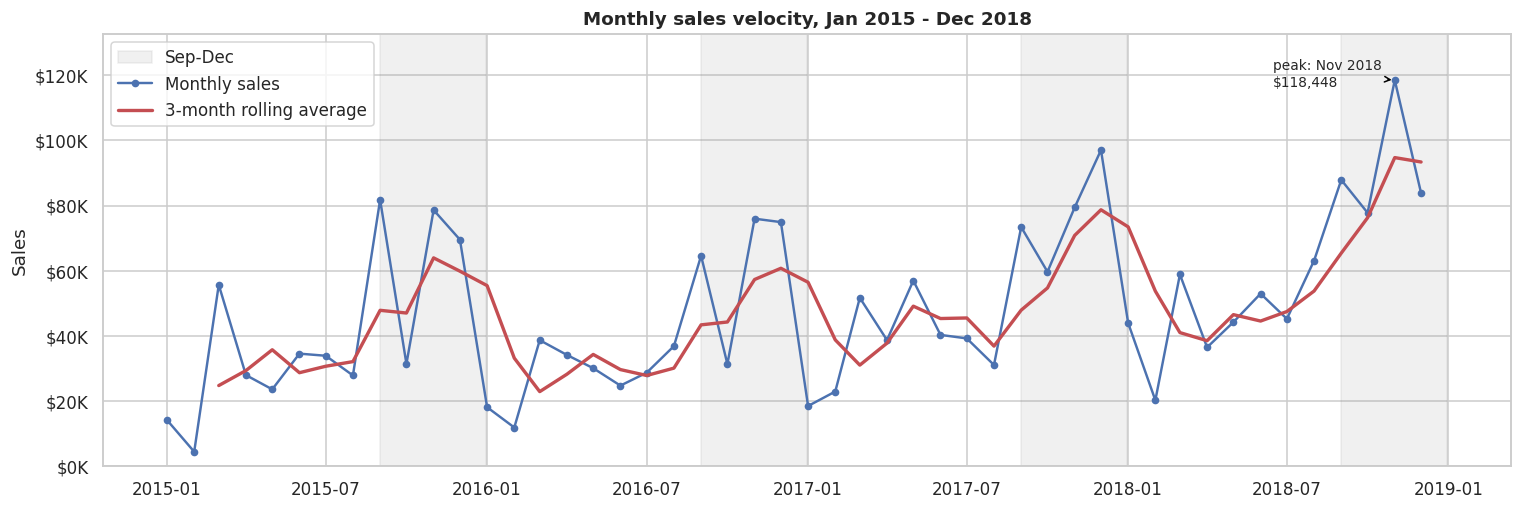

In [23]:
monthly = (df.groupby("Year-Month")
             .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique")))
monthly.index = monthly.index.to_timestamp()
monthly["Sales_3M_Avg"] = monthly["Sales"].rolling(3).mean()

fig, ax = plt.subplots(figsize=(14, 4.8))
for y in sorted(df["Year"].unique()):
    ax.axvspan(pd.Timestamp(y, 9, 1), pd.Timestamp(y, 12, 31), color=GREY, alpha=0.13,
               label="Sep-Dec" if y == df["Year"].min() else None)
ax.plot(monthly.index, monthly["Sales"], marker="o", ms=4, color=BLUE, lw=1.6, label="Monthly sales")
ax.plot(monthly.index, monthly["Sales_3M_Avg"], color=RED, lw=2.2, label="3-month rolling average")

peak = monthly["Sales"].idxmax()
ax.annotate(f"peak: {peak:%b %Y}\n${monthly['Sales'].max():,.0f}", (peak, monthly["Sales"].max()),
            textcoords="offset points", xytext=(-80, -4), fontsize=9, arrowprops=dict(arrowstyle="->", color="black"))
ax.yaxis.set_major_formatter(usd_k)
ax.set_ylim(0, monthly["Sales"].max() * 1.12)
ax.set_title("Monthly sales velocity, Jan 2015 - Dec 2018")
ax.set_ylabel("Sales")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

### 6.3 Seasonality
Each month is expressed relative to its own year's average month (index 1.0 = an average month). This removes the effect of year-on-year growth, so the four years can be compared fairly.

In [24]:
ym = df.groupby(["Year", "Month"])["Sales"].sum().unstack("Month")
ym.columns = [calendar.month_abbr[m] for m in ym.columns]
season_index = ym.div(ym.mean(axis=1), axis=0).mean()

top3_by_year = ym.apply(lambda r: ", ".join(r.nlargest(3).index), axis=1).rename("Top 3 months")
low2_by_year = ym.apply(lambda r: ", ".join(r.nsmallest(2).index), axis=1).rename("Bottom 2 months")
sep_dec_share = (ym[["Sep", "Oct", "Nov", "Dec"]].sum(axis=1) / ym.sum(axis=1) * 100).round(1)
print("Share of annual sales falling in Sep-Dec (%):", sep_dec_share.to_dict())
pd.concat([top3_by_year, low2_by_year], axis=1)

Share of annual sales falling in Sep-Dec (%): {2015: 54.0, 2016: 52.5, 2017: 50.8, 2018: 50.2}


,Top 3 months,Bottom 2 months
Year,,
2015,"Sep, Nov, Dec","Feb, Jan"
2016,"Nov, Dec, Sep","Feb, Jan"
2017,"Dec, Nov, Sep","Jan, Feb"
2018,"Nov, Sep, Dec","Feb, Apr"


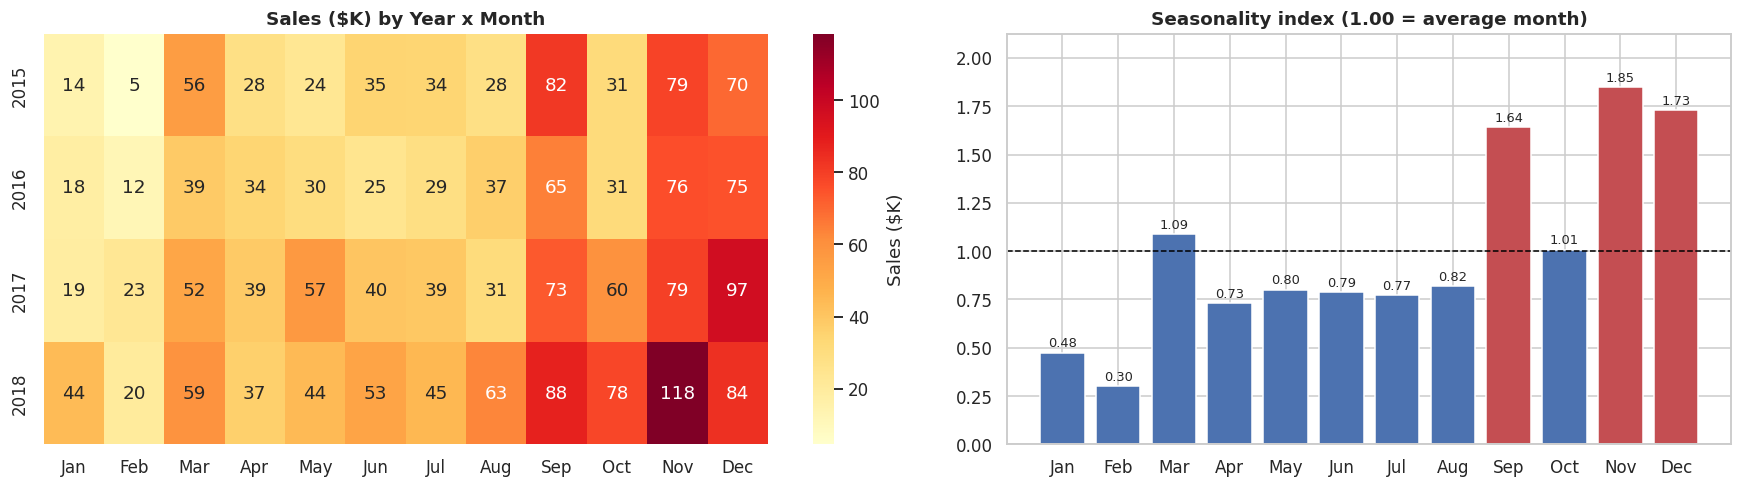

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})

sns.heatmap(ym / 1000, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "Sales ($K)"}, ax=axes[0])
axes[0].set_title("Sales ($K) by Year x Month")
axes[0].set_xlabel("")
axes[0].set_ylabel("")

top_months = season_index.nlargest(3).index
bar_colors = [RED if m in top_months else BLUE for m in season_index.index]
axes[1].bar(season_index.index, season_index.values, color=bar_colors)
axes[1].axhline(1, color="black", lw=1, ls="--")
for i, v in enumerate(season_index.values):
    axes[1].text(i, v + 0.03, f"{v:.2f}", ha="center", fontsize=8.5)
axes[1].set_title("Seasonality index (1.00 = average month)")
axes[1].set_ylim(0, season_index.max() * 1.15)

fig.tight_layout()
plt.show()

**Observations**
- **Sales grew strongly but not steadily:** 2016 dipped 2.8%, then 2017 grew 29.5% and 2018 20.4%. 2018 sales are 52% above 2015. Margin has sat at roughly 13% since 2016, so growth has come from volume rather than better economics.
- **Seasonality is strong and repeats every year.** September, November and December are the three biggest months in *every* year, and together with October they carry about 52% of annual sales. November runs at 1.85x an average month and February at 0.30x, a gap of about 6x.
- The **trough is Jan-Feb** (index 0.48 and 0.30, together under 7% of sales); they were the two weakest months in three of the four years. March is a smaller secondary bump (1.09).
- Peak-season concentration is gently easing (54% of 2015 sales fell in Sep-Dec vs 50% in 2018), which is consistent with the off-peak months growing faster.

## 7. Discount sensitivity
### 7.1 Profit by discount band

In [26]:
bins = [-0.001, 0, 0.10, 0.20, 0.30, 0.40, 0.50, 0.80]
labels = ["0%", "1-10%", "11-20%", "21-30%", "31-40%", "41-50%", "51-80%"]
df["Discount Band"] = pd.cut(df["Discount"], bins=bins, labels=labels)

bands = (df.groupby("Discount Band", observed=True)
           .agg(Lines=("Row ID", "count"), Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                Avg_Qty_per_Line=("Quantity", "mean"),
                Loss_Making_pct=("Profit", lambda s: (s < 0).mean() * 100))
           .assign(Margin_pct=lambda t: t["Profit"] / t["Sales"] * 100,
                   Lines_share_pct=lambda t: t["Lines"] / t["Lines"].sum() * 100))
bands

,Lines,Sales,Profit,Avg_Qty_per_Line,Loss_Making_pct,Margin_pct,Lines_share_pct
Discount Band,,,,,,,
0%,4798,"1,087,908.47","320,987.60",3.81,0.00,29.51,48.01
1-10%,94,"54,369.35","9,029.18",3.97,4.26,16.61,0.94
11-20%,3709,"792,152.89","91,756.30",3.74,13.99,11.58,37.12
21-30%,226,"102,945.28","-10,357.22",3.75,91.59,-10.06,2.26
31-40%,233,"130,911.24","-25,448.19",3.82,88.84,-19.44,2.33
41-50%,77,"64,403.51","-22,999.54",3.71,100.00,-35.71,0.77
51-80%,856,"64,228.74","-76,559.05",3.91,100.00,-119.20,8.57


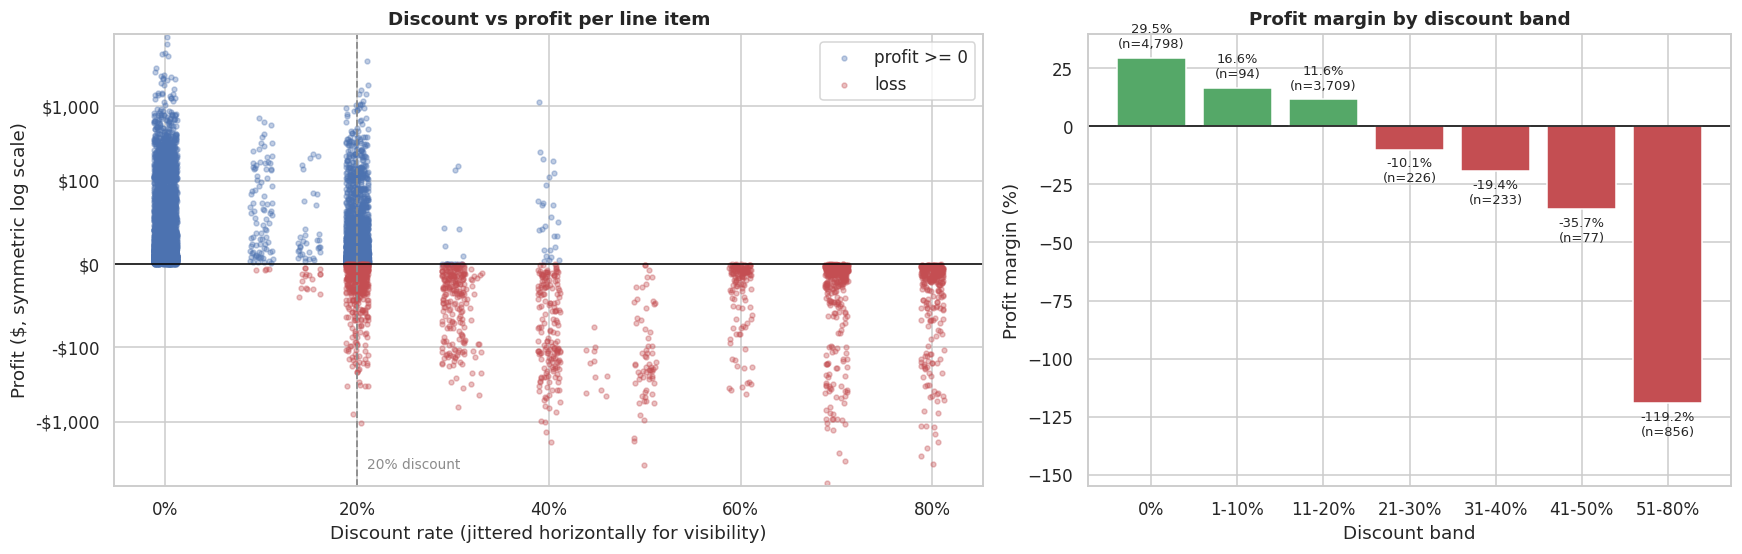

In [27]:
rng = np.random.default_rng(42)
jitter = rng.uniform(-0.012, 0.012, len(df))
is_loss = df["Profit"] < 0

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.35, 1]})

ax = axes[0]
ax.scatter(df.loc[~is_loss, "Discount"] + jitter[~is_loss], df.loc[~is_loss, "Profit"], s=10, alpha=0.35, color=BLUE, label="profit >= 0")
ax.scatter(df.loc[is_loss, "Discount"] + jitter[is_loss], df.loc[is_loss, "Profit"], s=10, alpha=0.35, color=RED, label="loss")
ax.axhline(0, color="black", lw=1)
ax.axvline(0.20, color=GREY, ls="--", lw=1.2)
ax.text(0.21, 0.04, "20% discount", color=GREY, fontsize=9, transform=ax.get_xaxis_transform())
ax.set_yscale("symlog", linthresh=100)
ax.set_title("Discount vs profit per line item")
ax.set_xlabel("Discount rate (jittered horizontally for visibility)")
ax.set_ylabel("Profit ($, symmetric log scale)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(usd)
ax.legend(loc="upper right")

ax = axes[1]
colors = [GREEN if m >= 0 else RED for m in bands["Margin_pct"]]
ax.bar(bands.index.astype(str), bands["Margin_pct"], color=colors)
ax.axhline(0, color="black", lw=1)
for i, (m, n_lines) in enumerate(zip(bands["Margin_pct"], bands["Lines"])):
    ax.text(i, m + (3 if m >= 0 else -3), f"{m:.1f}%\n(n={n_lines:,})", ha="center", va="bottom" if m >= 0 else "top", fontsize=8.5)
ax.set_ylim(bands["Margin_pct"].min() * 1.3, bands["Margin_pct"].max() * 1.35)
ax.set_title("Profit margin by discount band")
ax.set_xlabel("Discount band")
ax.set_ylabel("Profit margin (%)")

fig.tight_layout()
plt.show()

In [28]:
hi = df[df["Discount"] > 0.20]
lo = df[df["Discount"] <= 0.20]

print(f"Lines discounted above 20%: {len(hi):,} ({len(hi) / len(df):.1%} of lines), sales {money(hi['Sales'].sum())}, profit {money(hi['Profit'].sum())}")
print(f"  ...of which loss-making: {(hi['Profit'] < 0).mean():.1%}")
print(f"Lines discounted 20% or less: profit ${lo['Profit'].sum():,.0f} on sales ${lo['Sales'].sum():,.0f} (margin {lo['Profit'].sum() / lo['Sales'].sum():.1%})")
print(f"All lines together:          profit ${df['Profit'].sum():,.0f} (margin {df['Profit'].sum() / df['Sales'].sum():.1%})")
print()
print(f"Pearson  corr(discount, profit)        = {df['Discount'].corr(df['Profit']):+.2f}   (dragged toward zero by extreme outliers)")
print(f"Spearman corr(discount, profit)        = {df['Discount'].corr(df['Profit'], method='spearman'):+.2f}")
print(f"Pearson  corr(discount, profit margin) = {df['Discount'].corr(df['Profit'] / df['Sales']):+.2f}")
print(f"Pearson  corr(discount, quantity)      = {df['Discount'].corr(df['Quantity']):+.2f}   (does discounting buy more units per line?)")

Lines discounted above 20%: 1,392 (13.9% of lines), sales $362,489, profit -$135,364
  ...of which loss-making: 96.8%
Lines discounted 20% or less: profit $421,773 on sales $1,934,431 (margin 21.8%)
All lines together:          profit $286,409 (margin 12.5%)

Pearson  corr(discount, profit)        = -0.22   (dragged toward zero by extreme outliers)
Spearman corr(discount, profit)        = -0.54
Pearson  corr(discount, profit margin) = -0.86
Pearson  corr(discount, quantity)      = +0.01   (does discounting buy more units per line?)


### 7.2 Where is the heavy discounting happening?

In [29]:
def margin_pct(frame, by):
    g = frame.groupby(by)[["Profit", "Sales"]].sum()
    return g["Profit"] / g["Sales"] * 100

region_disc = (df.groupby("Region")
                 .agg(Avg_Discount_pct=("Discount", lambda s: s.mean() * 100),
                      Lines_over_20pct_disc=("Discount", lambda s: (s > 0.20).mean() * 100)))
region_disc["Margin_pct (all lines)"] = margin_pct(df, "Region")
region_disc["Margin_pct (lines <=20% disc)"] = margin_pct(lo, "Region")
region_disc = region_disc.sort_values("Lines_over_20pct_disc", ascending=False)
region_disc

,Avg_Discount_pct,Lines_over_20pct_disc,Margin_pct (all lines),Margin_pct (lines <=20% disc)
Region,,,,
Central,24.04,27.68,7.92,24.75
East,14.53,16.16,13.49,25.07
South,14.73,10.56,11.93,22.31
West,10.93,3.68,14.94,17.57


In [30]:
subcat_disc = (df.groupby(["Category", "Sub-Category"])
                 .agg(Avg_Discount_pct=("Discount", lambda s: s.mean() * 100),
                      Lines_over_20pct_disc=("Discount", lambda s: (s > 0.20).mean() * 100),
                      Sales=("Sales", "sum"), Profit=("Profit", "sum"))
                 .assign(Margin_pct=lambda t: t["Profit"] / t["Sales"] * 100)
                 .sort_values("Lines_over_20pct_disc", ascending=False))
subcat_disc.head(6)

Avg_Discount_pct  Lines_over_20pct_disc  \
Category        Sub-Category                                            
Furniture       Tables                   26.13                  55.17   
Technology      Machines                 30.61                  46.09   
Office Supplies Binders                  37.23                  40.25   
Furniture       Bookcases                21.11                  30.70   
                Chairs                   17.00                  25.49   
                Furnishings              13.83                  14.42   

                                  Sales     Profit  Margin_pct  
Category        Sub-Category                                    
Furniture       Tables       206,965.53 -17,725.48       -8.56  
Technology      Machines     189,238.63   3,384.76        1.79  
Office Supplies Binders      203,412.73  30,221.76       14.86  
Furniture       Bookcases    114,880.00  -3,472.56       -3.02  
                Chairs       328,167.73  26,602.23        8.11  
                Furnishings   91,705.16  13,059.14       14.24

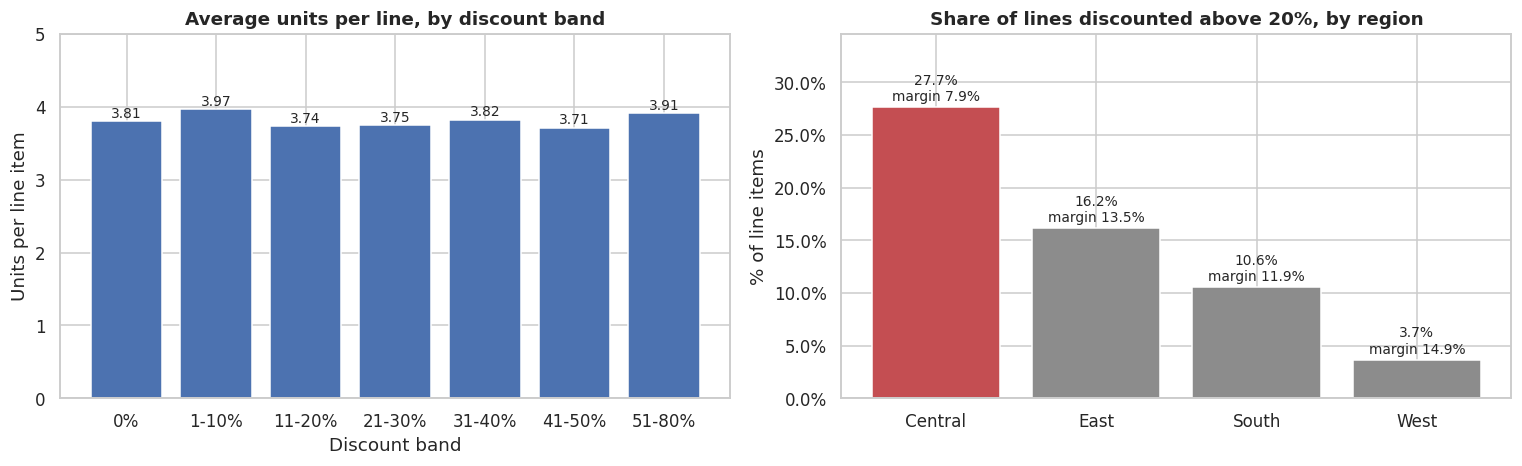

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))

# (a) does discounting buy volume?
axes[0].bar(bands.index.astype(str), bands["Avg_Qty_per_Line"], color=BLUE)
for i, v in enumerate(bands["Avg_Qty_per_Line"]):
    axes[0].text(i, v + 0.05, f"{v:.2f}", ha="center", fontsize=9)
axes[0].set_ylim(0, 5)
axes[0].set_title("Average units per line, by discount band")
axes[0].set_xlabel("Discount band")
axes[0].set_ylabel("Units per line item")

# (b) heavy-discount exposure by region
order = region_disc.sort_values("Lines_over_20pct_disc", ascending=False)
axes[1].bar(order.index, order["Lines_over_20pct_disc"], color=[RED if r == "Central" else GREY for r in order.index])
for i, (v, m) in enumerate(zip(order["Lines_over_20pct_disc"], order["Margin_pct (all lines)"])):
    axes[1].text(i, v + 0.6, f"{v:.1f}%\nmargin {m:.1f}%", ha="center", fontsize=9)
axes[1].set_ylim(0, order["Lines_over_20pct_disc"].max() * 1.25)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(100))
axes[1].set_title("Share of lines discounted above 20%, by region")
axes[1].set_ylabel("% of line items")

fig.tight_layout()
plt.show()

**Observations**
- **There is a cliff at 20%.** Undiscounted lines earn a 29.5% margin and lines at 1-20% still earn about 12%. Above 20% the average line loses money: -10% margin at 21-30% and -119% at 51-80%.
- **97% of lines discounted above 20% lose money.** They are 14% of lines (1,392) and $362K of sales, yet they subtract $135K of profit. Lines at 20% or below earn $422K on the same dataset (21.8% margin) versus the $286K reported overall.
- **Discounting is not buying volume:** units per line are flat across every band (about 3.7 to 4.0) and the discount-quantity correlation is about zero. Customers are not buying more because the price is lower, at least at line-item level.
- **Central is the heavy discounter:** 27.7% of its lines are discounted above 20% (West: 3.7%) and its average discount is 24% versus 11-15% elsewhere. Strip out those lines and Central's margin is 24.8%, level with East (25.1%). Its 7.9% headline margin is mostly a discount-discipline problem.
- West's margin lead comes from restraint rather than stronger underlying economics: on lines discounted 20% or less it earns 17.6%, the lowest of the four regions.
- **Tables (55% of lines above 20%), Machines (46%) and Binders (40%) are the most exposed sub-categories.** Binders absorb it (14.9% margin), Tables and Machines do not (-8.6% and 1.8%).

## 8. Returns cross-check
The stacked Returns sheet from Section 2 lets us check how much of the reported revenue was later returned. Sales and profit elsewhere in this notebook are **gross of returns**, because the orders table has no refund adjustment.

In [32]:
df["Returned"] = df["Order ID"].isin(returns["Order ID"])

order_level = (df.groupby("Order ID")
                 .agg(Region=("Region", "first"), Returned=("Returned", "first"), Sales=("Sales", "sum")))

n_orders = len(order_level)
n_returned = int(order_level["Returned"].sum())
returned_sales = order_level.loc[order_level["Returned"], "Sales"].sum()
print(f"Returned orders: {n_returned} of {n_orders:,} ({n_returned / n_orders:.1%})")
print(f"Sales on returned orders: ${returned_sales:,.0f} ({returned_sales / order_level['Sales'].sum():.1%} of total sales)")

ret_by_region = (order_level.groupby("Region")
                   .agg(Orders=("Returned", "size"), Returned_Orders=("Returned", "sum"))
                   .assign(Return_Rate_pct=lambda t: t["Returned_Orders"] / t["Orders"] * 100))
ret_by_region["Returned_Sales"] = order_level[order_level["Returned"]].groupby("Region")["Sales"].sum()
ret_by_region.sort_values("Return_Rate_pct", ascending=False)

Returned orders: 296 of 5,009 (5.9%)
Sales on returned orders: $180,504 (7.9% of total sales)


,Orders,Returned_Orders,Return_Rate_pct,Returned_Sales
Region,,,,
West,1611,189,11.73,"107,483.06"
Central,1175,39,3.32,"14,006.98"
East,1401,44,3.14,"41,705.14"
South,822,24,2.92,"17,309.10"


**Observation:** about 1 in 17 orders (5.9%, or $181K / 7.9% of sales) was returned. The rate is **not uniform: West returns 11.7% of its orders versus roughly 3% in each other region.** West is the strongest region on headline sales and margin, so its headline lead may be overstated until returns are netted out.

## 9. Executive takeaways

**1. Growth is real, but it is volume-led.** Sales rose from $484K (2015) to $733K (2018), +52%, with a flat 2016 followed by +29.5% and +20.4%. Profit margin has been stuck near 13% since 2016, so each extra dollar of revenue is not getting more profitable.
*Action: set a margin target alongside the revenue target.*

**2. Furniture is a revenue business, not a profit business.** It is 32% of sales but 6% of profit (2.5% margin). Tables (-8.6%) and Bookcases (-3.0%) lose money outright. Technology and Office Supplies together deliver 94% of profit at 17% margins.
*Action: reprice or renegotiate supplier cost on Tables and Bookcases; protect Technology and Office Supplies inventory.*

**3. Discounts above 20% are the single biggest profit leak.** 14% of line items carry them, 97% of those lose money, and together they lose $135K, equivalent to nearly half of the $286K total profit. They buy no extra volume (roughly 3.7 to 4.0 units per line at every discount level).
*Action: cap standard discounts at 20% and require approval above it.*

**4. Central's weak margin is a discount-discipline problem.** Central discounts above 20% on 28% of lines (West: 4%) and earns 7.9% margin versus 14.9% in West. Excluding the heavy-discount lines, its margin (24.8%) matches East (25.1%).
*Action: enforce the discount cap in Central first. It is the largest single prize.*

**5. Demand is highly seasonal and predictable.** September, November and December are the top three months in every year. Sep-Dec produce 52% of sales and November runs about 6x February. Jan-Feb deliver under 7%.
*Action: build inventory and staffing for Sep-Dec, and use targeted promotions to lift Jan-Feb rather than deep discounts in peak months.*

**6. The customer base is loyal but not equally valuable.** 98.5% of customers repeat-purchase (about 6 orders each), and the top 20% deliver 48% of sales, so no dangerous dependence on a few accounts. But 155 customers (20%) are net loss-making, including the largest customer by revenue.
*Action: review profitability per account, not just revenue, before approving large-account discounts.*

**Data caveat:** reported sales and profit include orders that were later returned (5.9% of orders, 7.9% of sales), and West's return rate (11.7%) is nearly four times that of the other regions. Net-of-returns figures would shift the West-vs-rest comparison.

## 10. Assumptions and limitations
- **Margin** is Profit / Sales, calculated on summed values (not an average of line-level margins).
- **"Customer" metrics** use `Customer ID`. Each Customer ID maps to exactly one name.
- **Discount findings are observational.** The data cannot show what volume would have been at a lower discount, only that higher discounts did not coincide with larger line quantities. Order-level or repeat-purchase effects are not tested.
- **Profit** is as reported in the source file. Its cost definition (COGS, shipping, overhead) is not documented.
- **Returns** are matched on Order ID. Return dates and refund amounts are not available, so returns are not netted from sales or profit anywhere in this analysis.
- **Seasonality** rests on four years of data; the pattern is consistent across all four, but treat the exact index values as indicative.